## Table of Contents

#### Part I: Research Question


A1. [Research Question](#A1.-Research-Question)

A2. [Goals](#A2.-Goals)

#### Part II: Method Justification


B1. [Summary of Assumptions](#B1.-Summary-of-Assumptions)

B2. [Tool Benefits](#B2.-Tool-Benefits)

B3. [Appropriate Technique](#B3.-Appropriate-Technique)

#### Part III: Data Preparation


C1. [Data Cleaning](#C1.-Data-Cleaning)

C2. [Summary Statistics](#C2.-Summary-Statistics)

C3. [Visualizations](#C3.-Visualizations)

C4. [Data Transformation](#C4.-Data-Transformation)

C5. [Prepared Data Set](#C5.-Prepared-Data-Set)

#### Part IV: Model Comparison and Analysis


D1. [Initial Model](#D1.-Initial-Model)

D2. [Justification of Model Reduction](#D2.-Justification-of-Model-Reduction)

D3. [Reduced Linear Regression Model](#D3.-Reduced-Linear-Regression-Model)

E1. [Model Comparison](#E1.-Model-Comparison)

E2. [Output and Calculations](#E2.-Output-and-Calculations)

E3. [Code](#E3.-Code)

#### Part V: Data Summary and Implications


F1. [Results](#F1.-Results)

F2. [Recommendations](#F2.-Recommendations)

#### Part VI: Sources



H. [Sources of Third-Party Code](#H.-Sources-of-Third-Party-Code)

I. [Sources](#I.-Sources)

### Part I: Research Question

#### A1. Research Question

The research question that will be addressed in this performance assessment is, "Which factors contribute to customer churn?" 

#### A2. Goals

The ultimate goal of this analysis is to understand which factors most strongly correlate with customer churn. Understanding the factors that contribute to a customer's decision to end their contract with the ISP can assist stakeholders in preventing churn and promoting customer retention. This is a vital interest to any business, as research has shown that acquiring new customers can be up to 25 times more expensive than acquiring new customers; additionally, the same research has shown that increasing overall customer retention by just 5% can increase profits anywhere from 25% to 95% (Gallo, 2014).

### Part II: Method Justification

#### B1. Summary of Assumptions 

There are a number of assumptions made when applying a logistic regression model; four of these assumptions are:

1. The response variable is binary; that is, the response variable only has two possible values. This is is appropriate for variables with valid values such as Yes/No, Male/Female, Pass/Fail, and so on.

2. The observations are independent. Each observation in the dataset is independent of the others; they should have no relation between each other, and no observation should occur only once with no repetitions.

3. Multicollinearity does not exist among the explanatory variables. This means that the explanatory variables must not be correlated with one another.

4. No extreme outliers exist. Outliers in the dataset could be overly influential when compared to other values, which could skew the results of the analysis.

(Bobbitt, 2020)

#### B2. Tool Benefits

For this analysis, I will be using Python to perform data cleaning, wrangling, and the logistic regression. Python is an open-source programming language, which is commonly used across both business and academia for data analytics. It is openly available and free to use, which makes it more accessible than paid alternatives such as SAS. (WGU School of Information Technology, n.d.)

Python also has a number of packages and libraries that are purpose-built for manipulating and analyzing data. These include Pandas, which allows for the importation of data into "dataframe" objects; Seaborn, which can create data visualizations based on these dataframes; and Statsmodels, which is a powerful open-source statistics library that contains, among other things, functionalities for logistic regression. (Pandas Documentation, 2024; Seaborn Documentation, 2024; Statsmodels Documentation, n.d.)

#### B3. Appropriate Technique

Logistic regression is a statistical technique that allows an analyst to determine the relationship between a set of one or more explanatory variables and a single categorical response variable which has two possible values. (Bobbitt, 2020).

Logistic regression is a suitable technique for addressing the research question set out in this assessment. As stated above, the research question is, "Which factors contribute to customer churn?" Customer churn is recorded as a boolean categorical variable in the Churn dataset, with valid values of Yes and No. As the Churn variable is a categorical variable with two possible values, logistic regression is appropriate for this use case.

### Part III: Data Preparation

#### C1. Data Cleaning

I will be re-using the same data cleaning code that I used for my previous performance assessment for this course. This code is designed to be modular and comprehensive; it's purpose built to thoroughly identify and correct multiple types of data issues across various data types. This includes functionality to correct missing data, invalid values, and outliers. It has already been configured to address and clean the Churn dataset.

The code operates in three core steps. In the first step, duplicate records are identified; this includes both records that are "full duplicates" - that is, records that match on all columns - and "partial duplicates" - records that match specifically on columns that should be unique. All duplicates are printed out for the analyst to take further action on if required.

The second step checks for missing or malformed data; this is done across all columns. Data that is missing, formatted incorrectly, or that falls outside of expected values are identified. Data that falls into these categories are also printed out for the analyst to evaluate.

The third and final step identifies and drops outliers for all continuous numeric variables. Outliers are defined as values that are either 1.5 * IQR above the third quartile, or 1.5 * IQR below the first quartile. 

Ultimately, the goal when performing these cleaning steps is to make certain that the dataset used to build the logistic regression model is complete and populated only with accurate data.

In [1]:
# Import necessary packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

# Import the dataset
churnfile = pd.read_csv('../data/churn_clean.csv',index_col=0, keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

# Data quality check: Find complete dupes
churnfile_compldupes = churnfile.duplicated()
print("Complete dupes: " + str(churnfile_compldupes.any()))

# Data quality check: Look for dupes on columns that should be unique
uniquecols = ['Customer_id','Interaction']
for cols in (uniquecols):
    churnfile_uniqdupes = churnfile.duplicated(subset=cols, keep=False)
    print("Dupes in column " + cols + ": " + str(churnfile_uniqdupes.any()))

# Data quality check: Look for missing data
missingcols = []
for cols in churnfile:
    if ((churnfile[cols].isnull().sum()) > 0):
        missingcols.append(cols)
if len(missingcols) > 0:
    print("Columns that are missing data: ")
    print(missingcols)
else:
    print("No missing data found")

# Data quality check: Find non-boolean values in boolean vars
boolvars = ['Churn','Techie','Port_modem','Tablet','Phone','Multiple',
            'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
            'StreamingTV','StreamingMovies','PaperlessBilling']
badbools = []
for col in boolvars:
    if churnfile[col][~churnfile[col].isin(["Yes","No"])].any() == True:
        badbools.append(col)
if len(badbools) > 0:
    print("Boolean columns that have out-of-range values: ")
    print(badbools)
else:
    print("No invalid boolean values found")        
    
# Data quality check: Find invalid categorical values
rangecols = {"Gender":['Male','Female','Nonbinary'],
             "Marital":['Married','Separated','Divorced','Never Married','Widowed'],
             "Area":["Rural","Urban","Suburban"],
             "Contract":["One year","Two Year","Month-to-month"],
             "InternetService":["Fiber Optic","DSL","None"],
             "PaymentMethod":["Bank Transfer(automatic)","Credit Card (automatic)",
                              "Electronic Check","Mailed Check"]
            }
badrange = []
for col, val in rangecols.items():
    if churnfile[col][~churnfile[col].isin(val)].any() == True:
        badrange.append(col)
if len(badrange) > 0:
    print("Categorical columns that have invalid values: ")
    print(badrange)
else:
    print("No invalid categorical values found")
    

# Find and remove outliers
# Bandwidth_GB_Year
# Outage_sec_perweek
# Population
# Tenure

for col in ['Bandwidth_GB_Year','Outage_sec_perweek','Population','Tenure']:
    Q3 = np.percentile(churnfile[col], 75)
    Q1 = np.percentile(churnfile[col], 25)
    
    IQR = (Q3-Q1)
    
    lowerlimit = Q1-(1.5*IQR)
    upperlimit = Q3+(1.5*IQR)
    
    churnfile.drop(churnfile[churnfile[col] > upperlimit].index, inplace=True)
    churnfile.drop(churnfile[churnfile[col] < lowerlimit].index, inplace=True)
    
    print("Outliers removed for " + col)

Complete dupes: False
Dupes in column Customer_id: False
Dupes in column Interaction: False
No missing data found
No invalid boolean values found
No invalid categorical values found
Outliers removed for Bandwidth_GB_Year
Outliers removed for Outage_sec_perweek
Outliers removed for Population
Outliers removed for Tenure


#### C2. Summary Statistics

Descriptive statistics for the response variable, Churn, are included below. This is a boolean categorical variable with valid values of "Yes" and "No"; it represents whether a customer has ended service with the ISP within the last month. There are 8999 total records in the dataset; 6603 have a value of "No" in the Churn field, while 2396 have a value of "Yes."

Summary statistics for the explanatory variables have also been printed below; these variables are Area, Bandwidth_GB_Year, Yearly_equip_failure, Techie, Contract, Port_modem, Tablet, InternetService, Phone, Multiple, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Outage_sec_perweek, Population, and Tenure.

Area is a categorical variable with three possible values: Rural, Suburban, and Urban. Total counts for these values are relatively close across the datatset: there are 2988 Rural records, 3001 Suburban, and 3010 Urban.

Bandwidth_GB_Year is a continuous variable, and is a measure of the annual bandwidth usage, in gigabytes, for each customer. Across all 8999 records, the values in this column range from 155.50 gigabytes on the low end, up to 7158.98 gigabytes on the high end. The average bandwidth used in a year is 3403.03 gigabytes; the median is 3419.03 gigabytes. 

Yearly_equip_failure is a numeric variable showing the total number of equipment failures the customer has suffered in a given year. The values range from 0 to 6. The vast majority of customers - 6058 out of the 8999 in the dataset - have never had an equipment failure, and have a value of 0 in this column. The number of customers dwindles as the count of equipment failures rises: 2393 customers have had 1 failure, 464 have had 2, 77 have had 3, 6 have had 4, and just 1 has had 6 failures. No customers have had 5 failures. The average for this column is around 0.39 yearly failures, and the median is 0.

Techie is a boolean column with valid values of Yes and No. This column indicates whether the customer is technically capable. Most customers do not feel they are techies; 7480 records have a No for this column, with 1519 answering yes.

Contract is a categorical variable indicating the type of service contract the customer has with the ISP. Valid values are Month-to-month, Two Year, and One Year. 4924 customers have a month to month contract; 2168 have a two year contract; and 1907 have a one year contract.

Port_modem is a boolean column with valid values of Yes and No. This field indicates whether or not the customer has a portable modem. 4657 records do not have a portable modem; 4342 do have one.

Tablet is a boolean column with valid values of Yes and No. This indicates whther a customer has a tablet. 6293 records show no tablet; 2706 do have a tablet.

InternetService is a categorical variable indicating the type of internet service the customer has. Valid values for this column are Fiber Optic, DSL, and None. 3970 records show Fiber Optic; 3113 have DSL; 1916 have None.

Phone is a boolean column with valid values of Yes and No. This field indicates whether a customer has home phone service. The overwhelming majority of customers do have phone service, with 8162 records showing a Yes in this column; just 837 have no phone.

Multiple is a boolean column with valid values of Yes and No. This column shows whether or not a customer has multiple phone lines. 4842 customers have a No in this column while 4157 have a Yes.

OnlineSecurity is a boolean column with valid values of Yes and No. This shows whether or not a customer subscribes to the ISP's online security add-on package. 5782 customers do not have this add-on; 3217 do have it.

OnlineBackup is a boolean column with valid values of Yes and No. This indicates whether the customer subscribes to the ISPs online data backup add-on package. 4948 records show a value of No; 4051 records have a value of Yes.

DeviceProtection is a boolean column with valid values of Yes and No. This column indicates whether the customer subscribes to the ISP's device protection plan. 5050 records show No; 3949 records show Yes.

TechSupport is a boolean column with valid values of Yes and No. The column shows whether the customer subscribes to the ISP's tech support add-on plan. 5625 customers do not subscribe to this plan; 3374 do subscribe to it.

StreamingTV is a boolean column with valid values of Yes and No. This shows whether or not the customer subscribes to the ISP's streaming television add-on package. 4554 records show the customer does not subscribe to the streaming TV service; 4445 records show that the customer does subscribe to it.

StreamingMovies is a boolean column with valid values of Yes and No. This shows whether the customer subscribes to the ISP's movie streaming add-on service. 4564 records show a value of No; 4435 records show a value of Yes.

Outage_sec_perweek is a continuous variable that is a measure of the average amount of seconds per week that a customer has suffered a service outage. The average for this value is 9.99 seconds; the range is from 2.09 seconds at the lowest end, all the way up to 17.86 seconds at the highest. The median is 10 seconds.

Population is a continuous variable showing the total population within a mile radius of the customer's residence. The values in this column range from 0 to 31860. The average is 6039.47, and the median is 2275.

Tenure is a continuous variable showing the number of months that the customer has actively been subscribed with the ISP. The lowest value in this column is 1 month; the highest value is 71.99 months. The average customer tenure is 34.64 months, and the median is 37.04 months. 

In [2]:
# Print descriptive statistics for Outage_sec_perweek
print("Descriptive statistics for the response variable, Churn:")
print(churnfile['Churn'].describe())
print(churnfile['Churn'].value_counts())
print("\n")


# Print descriptive statistics for explanatory vars
explan_vars = ["Area","Bandwidth_GB_Year","Yearly_equip_failure","Techie",
               "Contract","Port_modem","Tablet","InternetService","Phone",
               "Multiple","OnlineSecurity","OnlineBackup","DeviceProtection",
               "TechSupport","StreamingTV","StreamingMovies",
               "Outage_sec_perweek","Population","Tenure"]

print("Descriptive statistics for explanatory variables:")
print("\n")
for var in explan_vars:
    print("Statistics for " + var)
    print(churnfile[var].describe())
    print(churnfile[var].value_counts())
    print("\n")

Descriptive statistics for the response variable, Churn:
count     8999
unique       2
top         No
freq      6603
Name: Churn, dtype: object
Churn
No     6603
Yes    2396
Name: count, dtype: int64


Descriptive statistics for explanatory variables:


Statistics for Area
count      8999
unique        3
top       Urban
freq       3010
Name: Area, dtype: object
Area
Urban       3010
Suburban    3001
Rural       2988
Name: count, dtype: int64


Statistics for Bandwidth_GB_Year
count    8999.000000
mean     3403.032287
std      2184.473515
min       155.506715
25%      1238.368638
50%      3419.036940
75%      5593.110247
max      7158.981530
Name: Bandwidth_GB_Year, dtype: float64
Bandwidth_GB_Year
904.536110     1
800.982766     1
2054.706961    1
2164.579412    1
271.493436     1
              ..
5270.238451    1
4945.756430    1
6511.252601    1
4159.305799    1
5857.586167    1
Name: count, Length: 8999, dtype: int64


Statistics for Yearly_equip_failure
count    8999.000000
mean   

#### C3. Visualizations

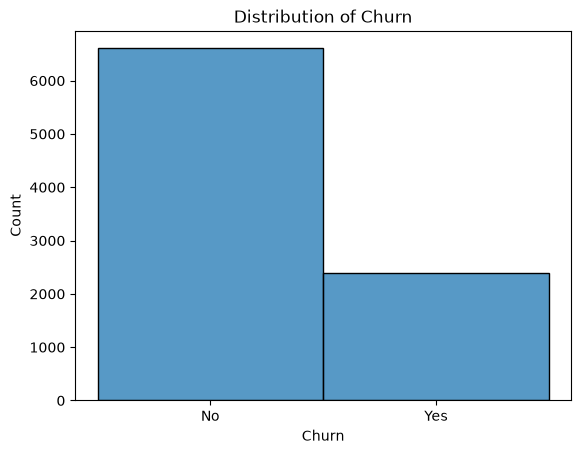

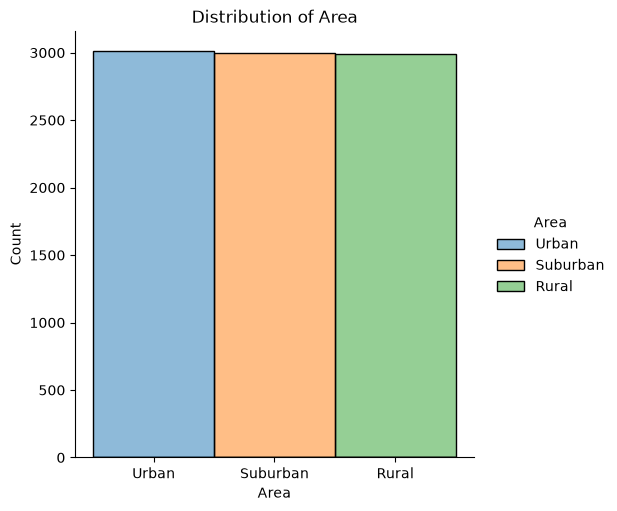

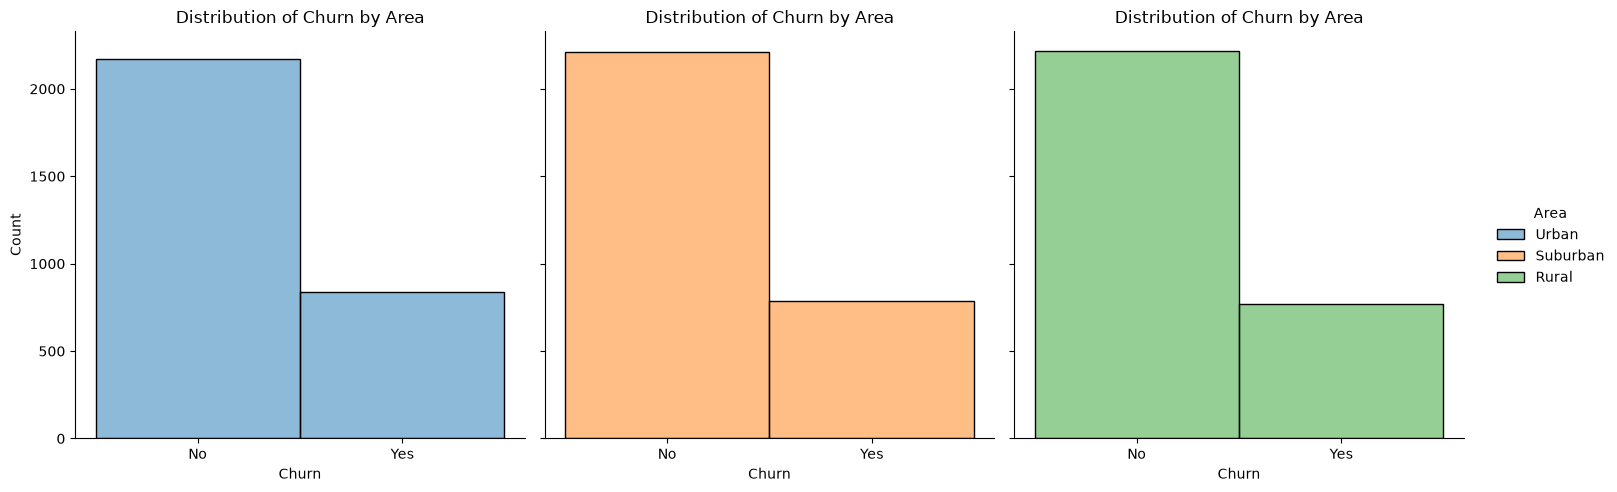

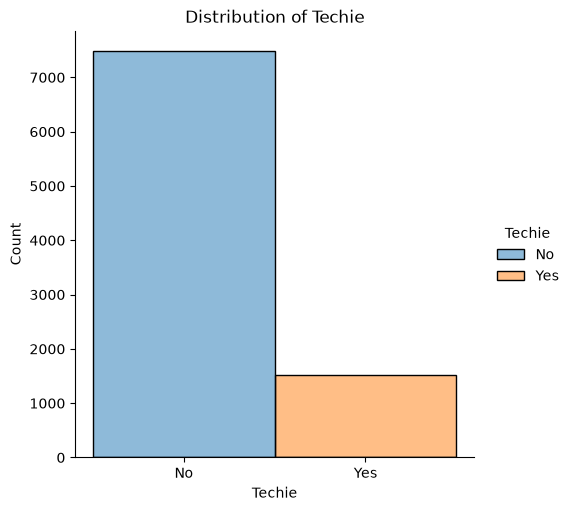

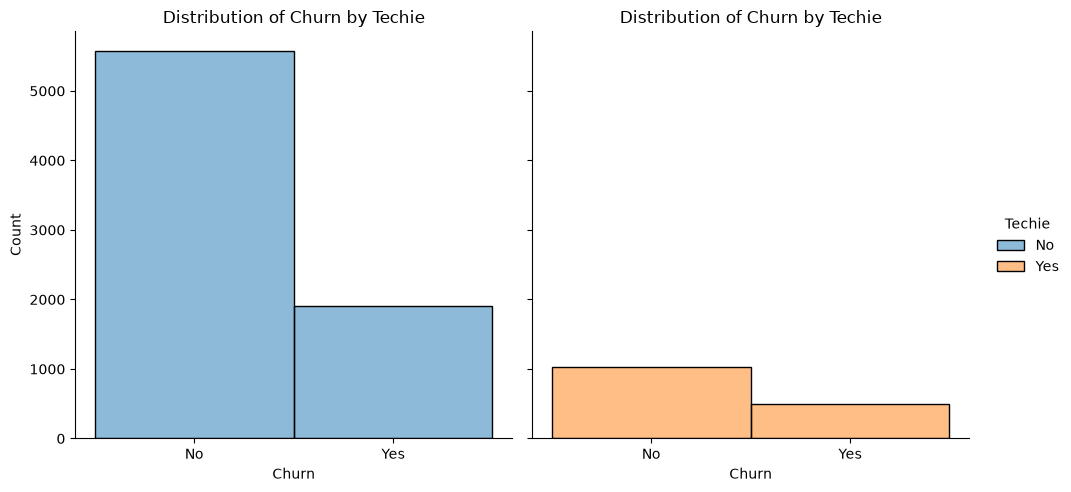

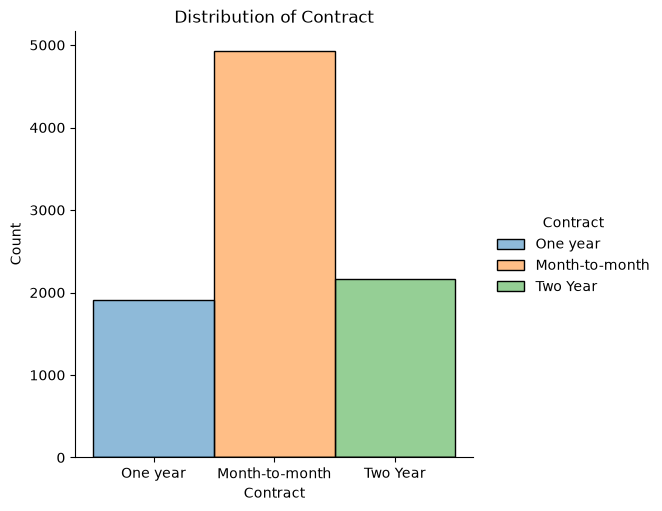

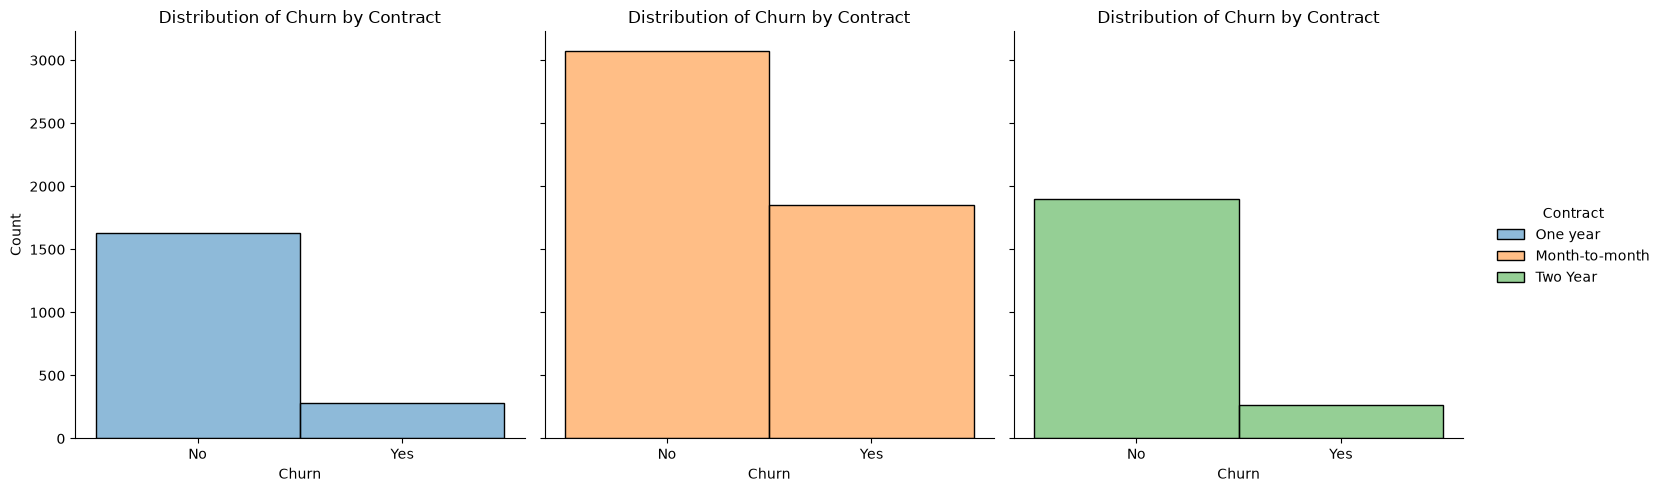

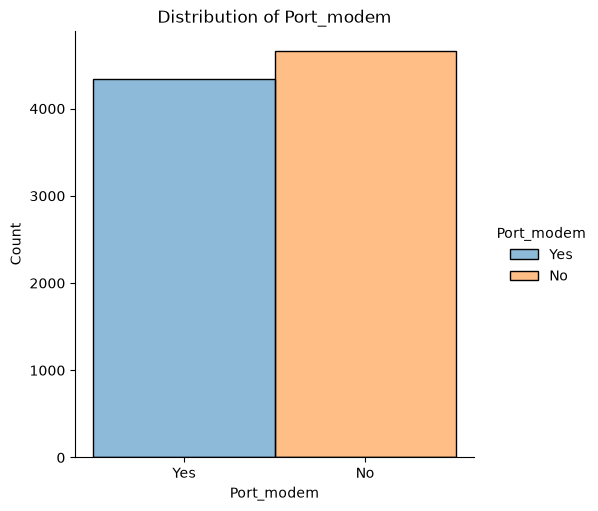

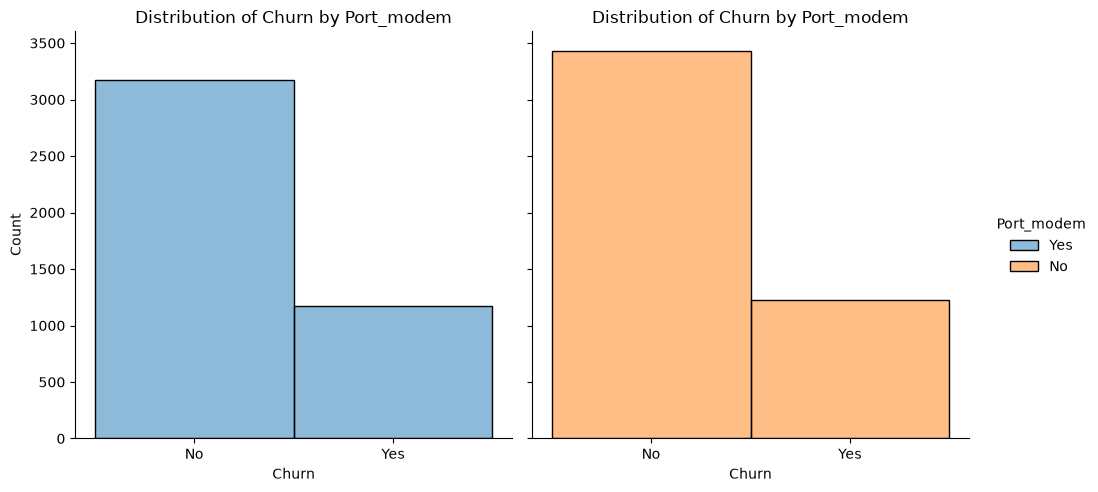

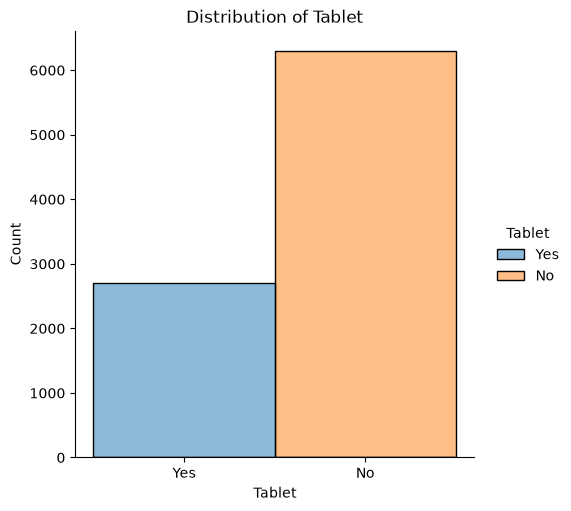

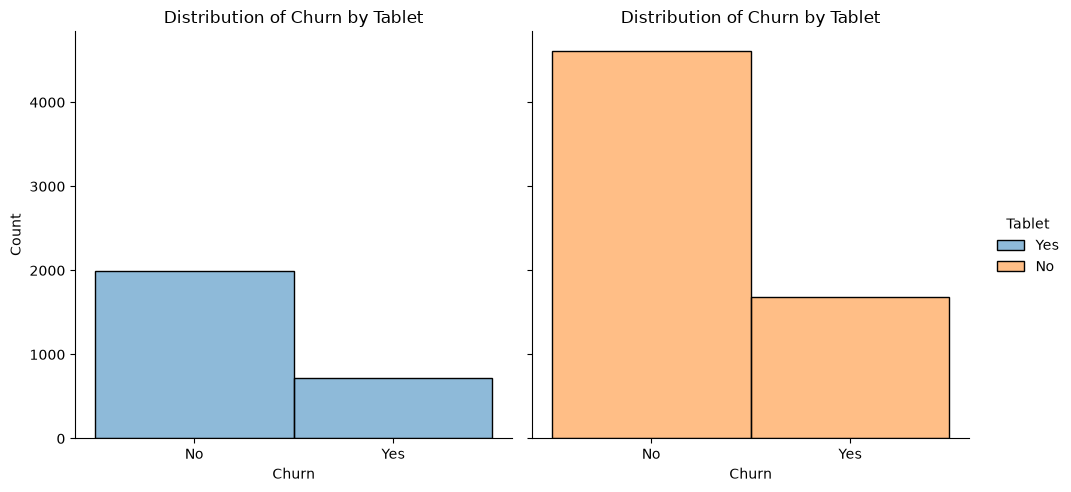

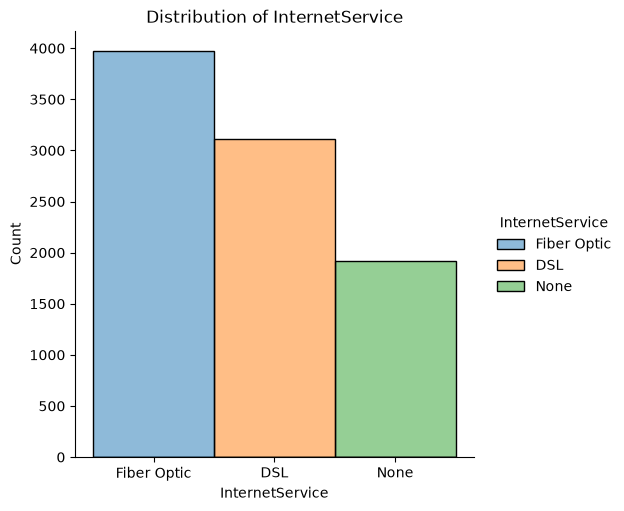

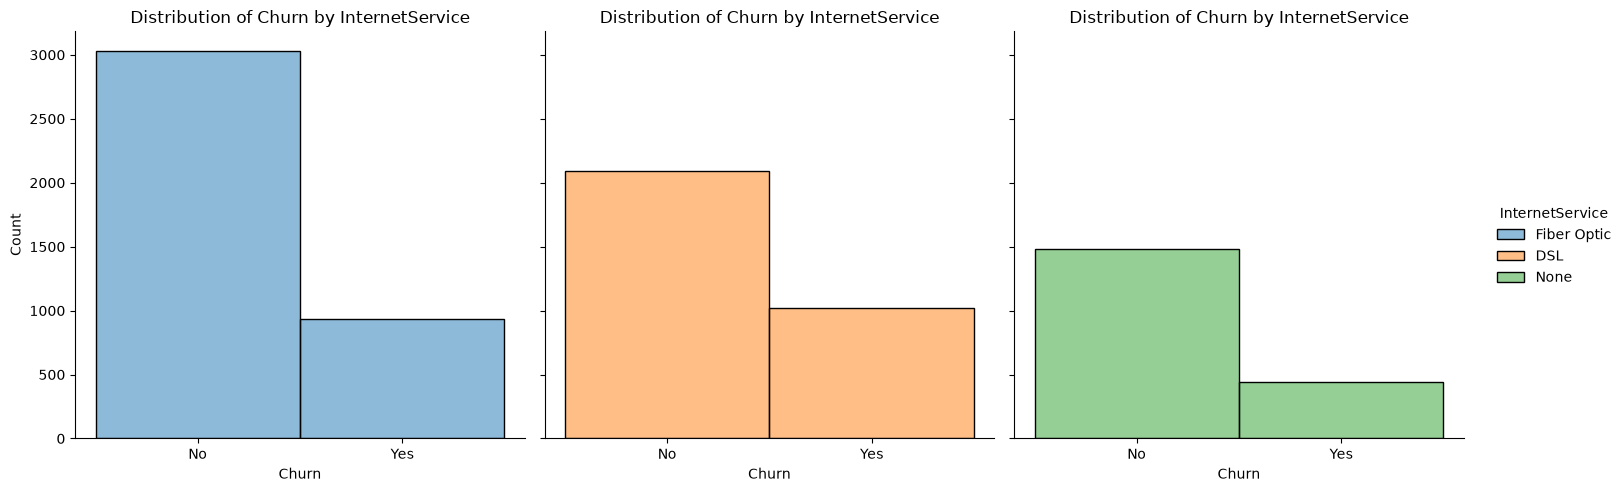

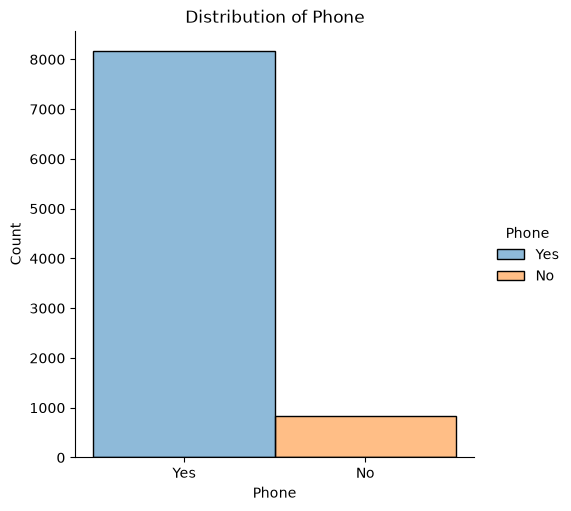

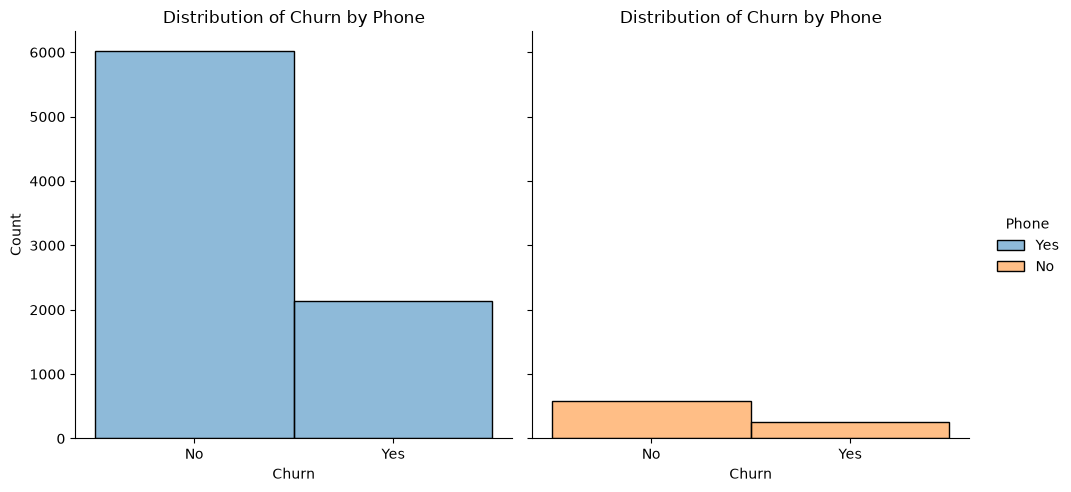

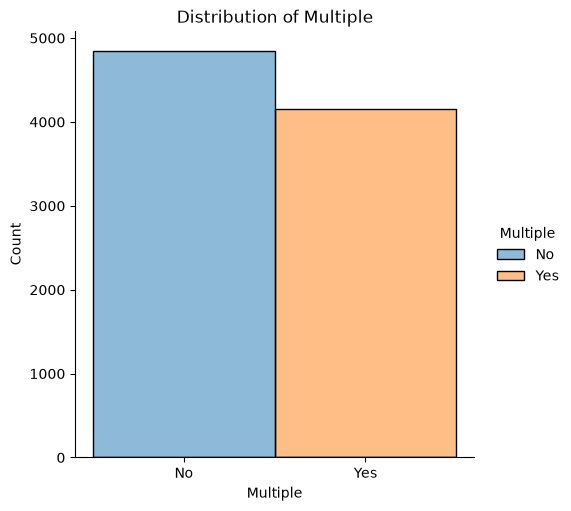

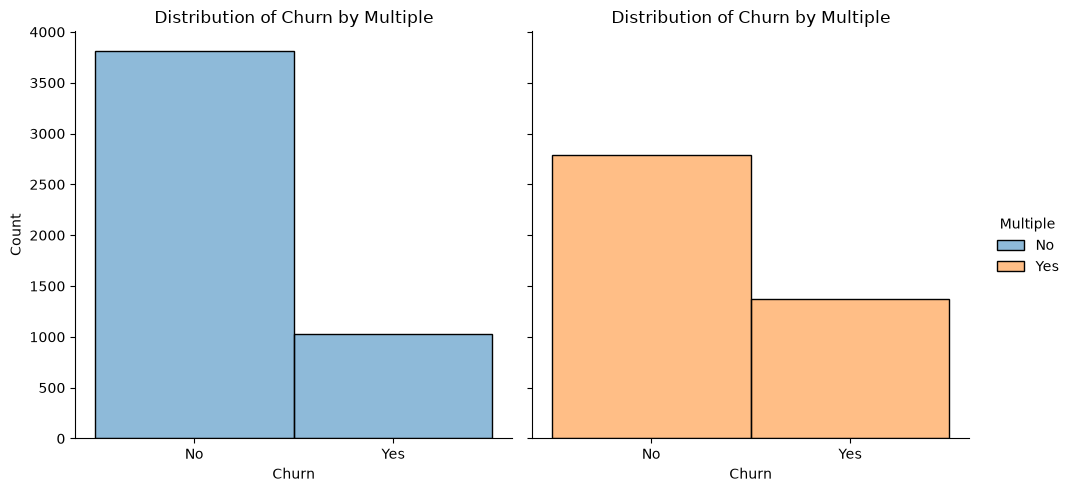

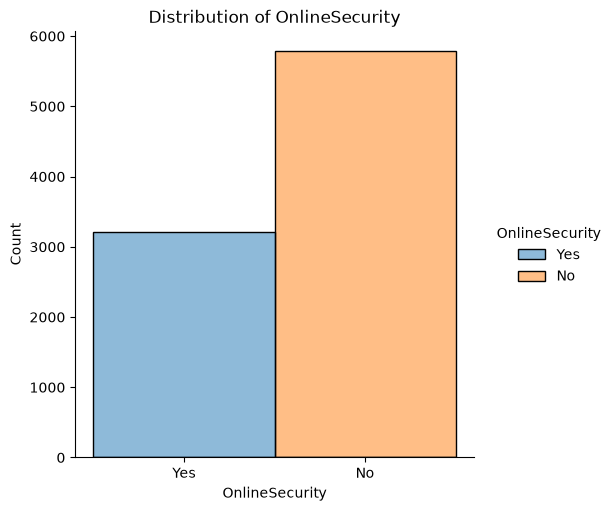

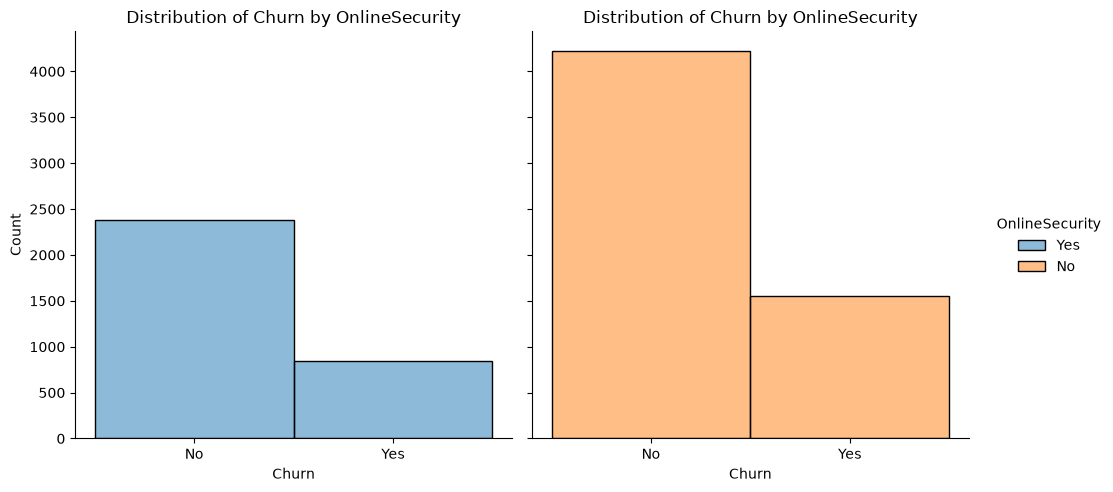

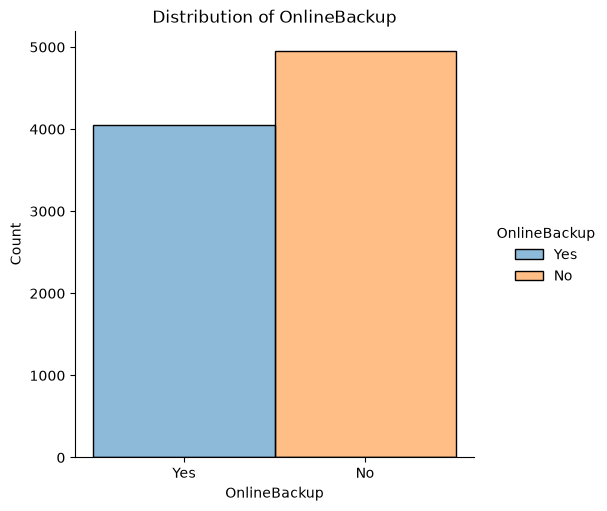

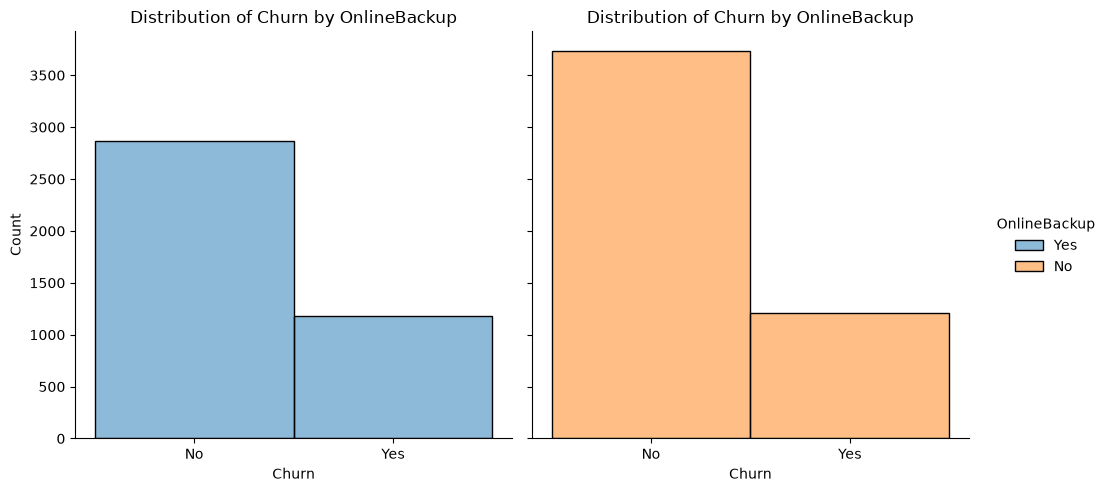

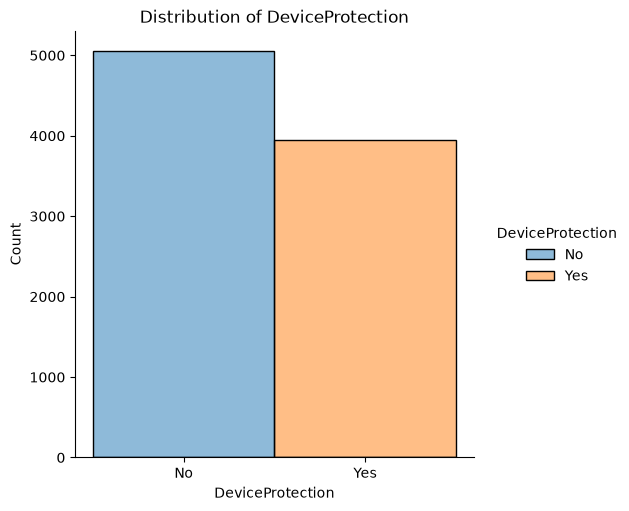

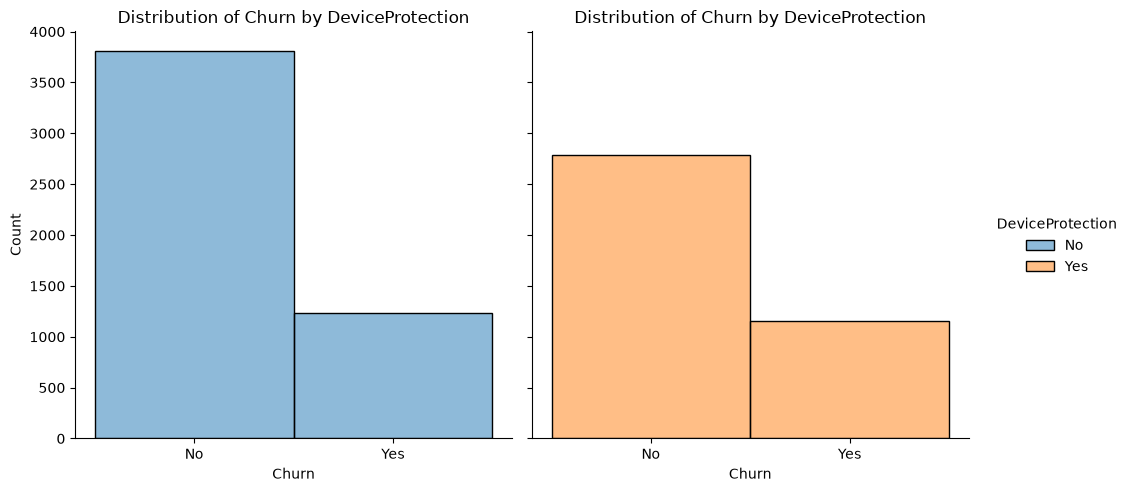

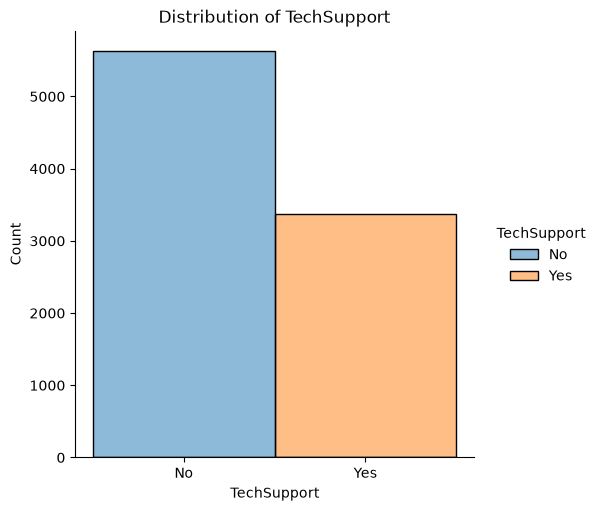

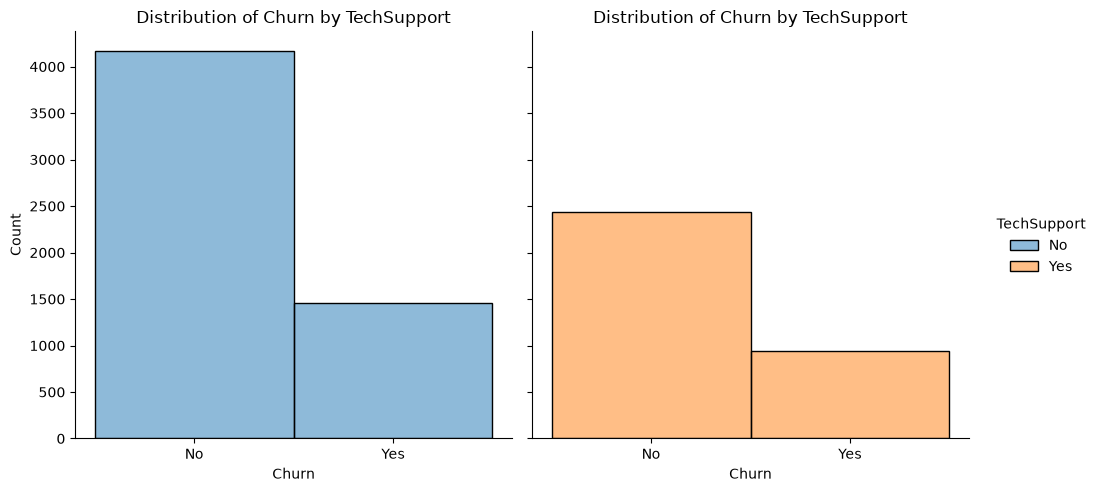

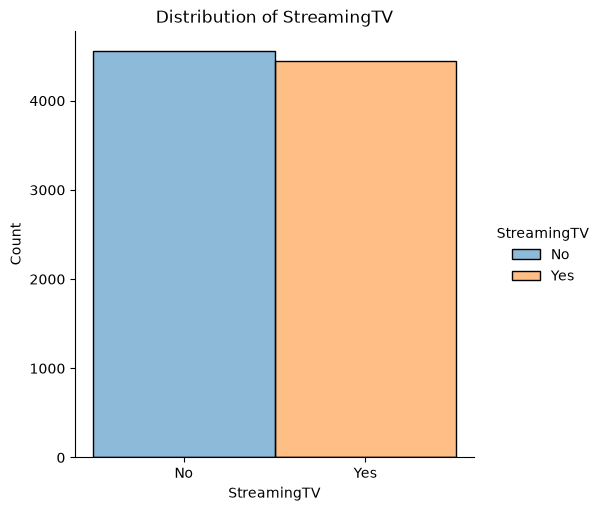

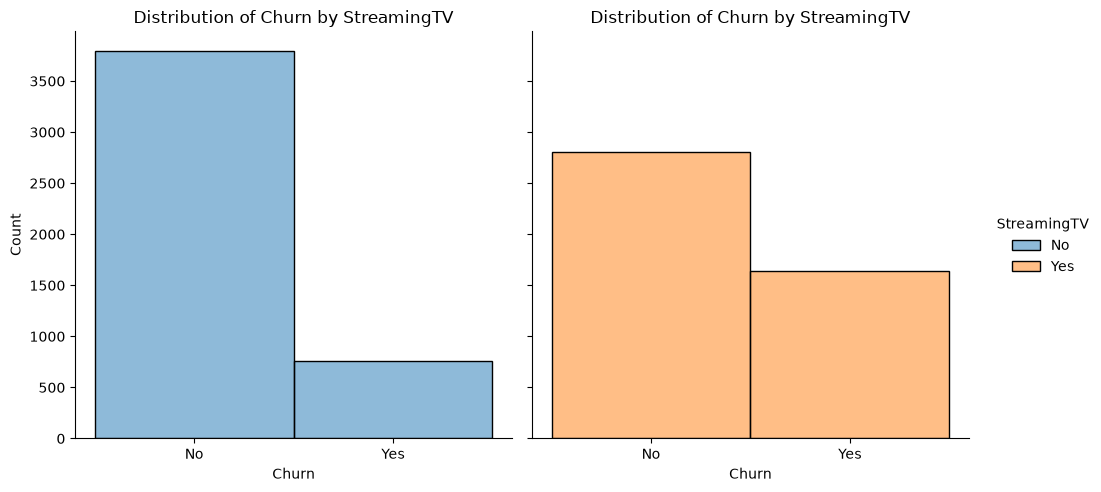

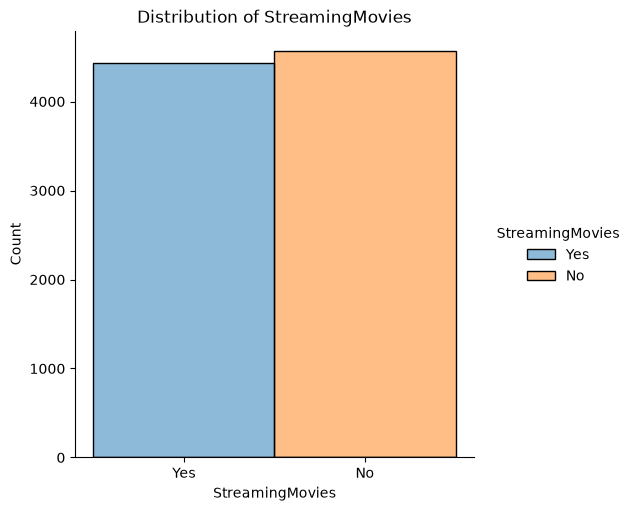

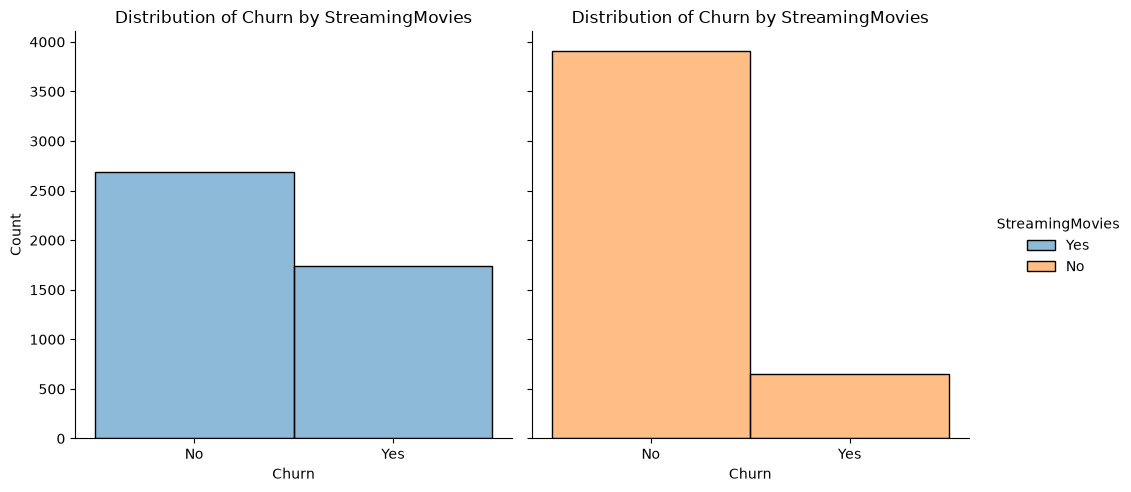

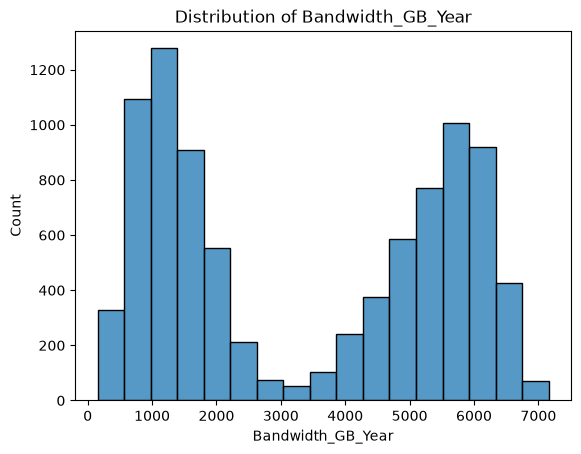

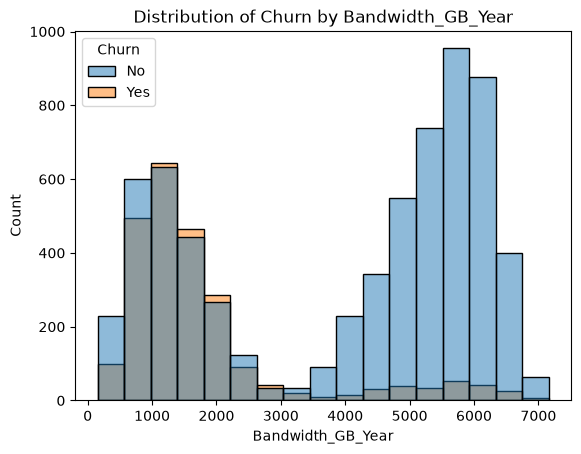

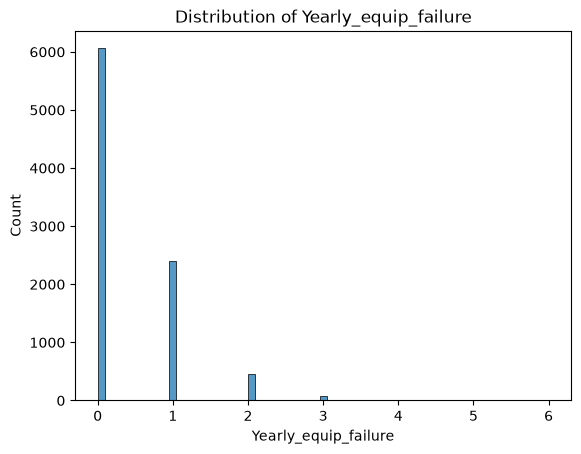

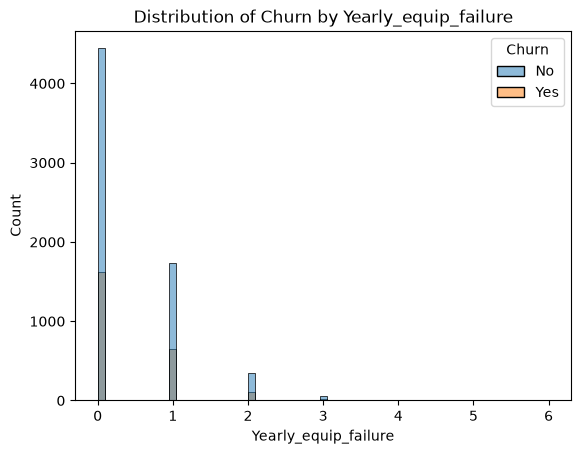

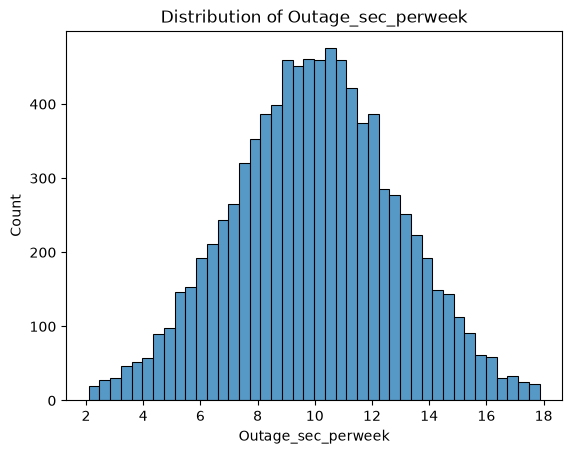

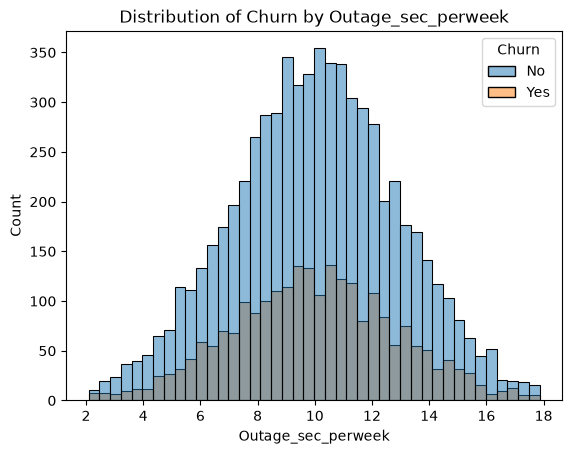

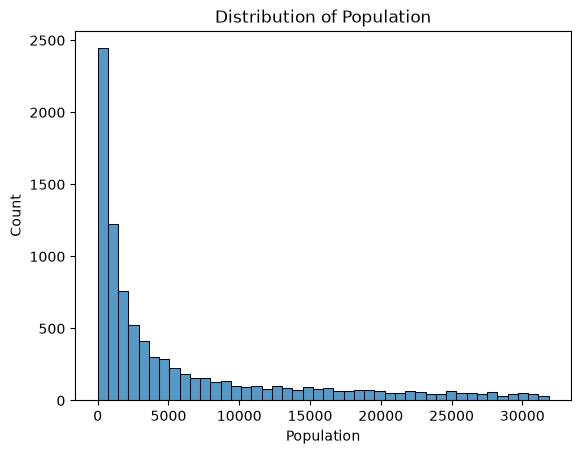

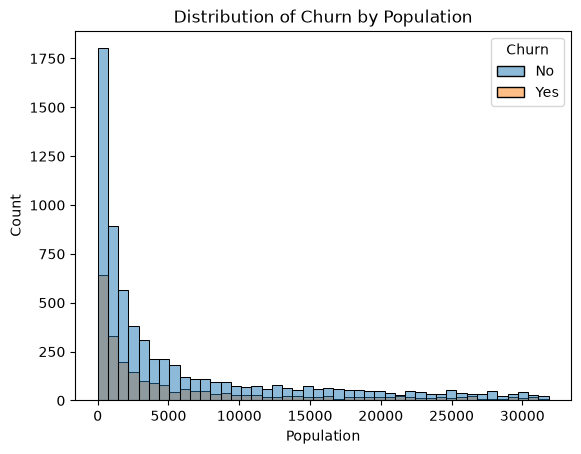

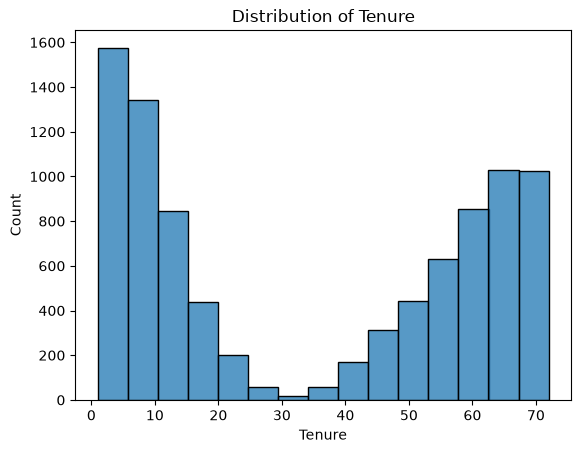

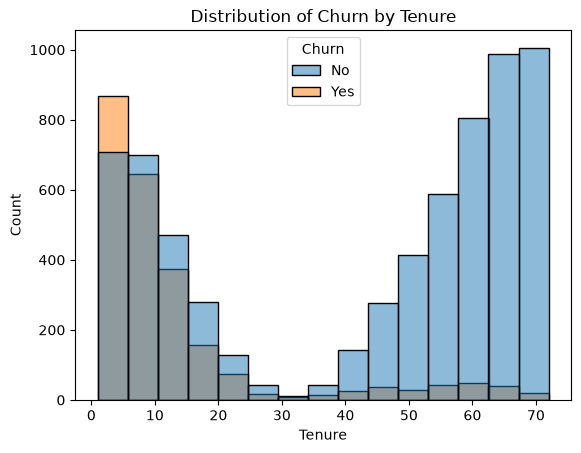

In [3]:
#Univariate and Bivariate Visualizations

explan_var_cat = ["Area","Techie","Contract","Port_modem","Tablet",
                  "InternetService","Phone","Multiple","OnlineSecurity","OnlineBackup",
                  "DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]

explan_var_cont = ["Bandwidth_GB_Year","Yearly_equip_failure","Outage_sec_perweek","Population","Tenure"]

# Distribution of response variable, Bandwidth_GB_Year
sns.histplot(data=churnfile, x='Churn').set(title="Distribution of Churn")
plt.pyplot.show()

# Univariate and Bivariate distributions of categorical explanatory variables
for var in explan_var_cat:
    sns.displot(data=churnfile, x=var,hue=var).set(title="Distribution of " + var)
    sns.displot(data=churnfile, x='Churn', hue=var, col=var).set(title="Distribution of Churn by " + var)
    plt.pyplot.show()

# Univariate and Bivariate distributions of continuous explanatory variables
for var in explan_var_cont:
    sns.histplot(data=churnfile, x=var, legend=False).set(title="Distribution of " + var)
    plt.pyplot.show()
    sns.histplot(data=churnfile, x=var, hue='Churn').set(title="Distribution of Churn by " + var)
    plt.pyplot.show()

#### C4. Data Transformation

Transforming the data is a necessary step in order to prepare the data before attempting to create the initial logistic regression model. All boolean categorical columns must be changed from Yes or No to their numeric equivalents (in this case, 1 and 0). This will be done with the variables Churn, Techie, Port_modem, Tablet, Phone, Multiple, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, and PaperlessBilling.

One-hot encoding will be used to modify the categorical variables within the dataset. This will mean replacing each categorical column with new boolean columns for each potential value of the originating categorical column. Multicollinearity will be addressed by using K-1 encoding; this means creating one less column, and instead indicating that specific value by populating each of the other columns with zeroes. For example, the explanatory variable "Contract" has three potential values: One Year, Two Year, and Month-by-Month. Two new boolean columns, "Contract_One year" and "Contract_Two Year", will be created instead; a value of 1 in either field will indicate what type of contract the customer has. Values of zeroes in both fields will indicate a Month-by-Month contract type. One-hot encoding will be used for the Area, Contract, and InternetService columns.

Finally, a dataset will be created containing only the variables required for the logistic regression model. This includes all explanatory variables used in the analysis, which are listed above, along with the response variable, Churn. The "kitchen sink" approach has been utilized here, meaning that a relatively large number of explanatory variables have been selected for use the initial model without regard for their apparent relevance to the research question. An initial logistic regression model will be built using these variables, and then the model will be improved by removing the least statistically relevant variables one at a time, until the model has improved to such an extent that it is statistically and practically viable.

As with the data cleaning code above, the data transformation code below has been reutilized from my previous performance assessment for this course, with a few changes to account for different variables being included. This code is flexible enough to be reused here to accomplish the transformation goals that are needed for the logistic regression model.

In [4]:
# Convert Yes/No String Values to Numeric 1/0
for var in boolvars:
    churnfile[var] = churnfile[var].replace({"No": 0, "Yes": 1})

# Use One-Hot Encoding to Convert Categorical Variables to Numeric
# drop_first = True for k-1
churn_ohe = pd.get_dummies(churnfile, prefix="Area", columns=["Area"], drop_first=True, dtype=int)         
churn_ohe = pd.get_dummies(churn_ohe, prefix="Contract", columns=["Contract"], drop_first=True, dtype=int)     

# Apply OHE to InternetService separately so that values of None are mapped to all zeroes
# Without this the output OHE columns are Fiber Optic and None; for readability we prefer DSL and FiberOptic
InternetService_ohe = pd.get_dummies(churn_ohe["InternetService"], dtype=int).drop('None', axis=1)

# Append InternetService_ohe to churn_ohe
churn_appended = pd.concat([churn_ohe,InternetService_ohe],axis=1)

# Grab only the columns we need for initial logistic regression model
churn_regress_initial = churn_appended[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Churn","Contract_Two Year","Port_modem","Tablet","Fiber Optic",
                                        "DSL","Phone","Multiple","OnlineSecurity","OnlineBackup","DeviceProtection",
                                        "TechSupport","StreamingTV","StreamingMovies","Bandwidth_GB_Year",
                                        "Outage_sec_perweek","Population","Tenure"]]

print(churn_regress_initial)

           Area_Suburban  Area_Urban  Yearly_equip_failure  Techie  \
CaseOrder                                                            
1                      0           1                     1       0   
2                      0           1                     1       1   
3                      0           1                     1       1   
4                      1           0                     0       1   
5                      1           0                     1       0   
...                  ...         ...                   ...     ...   
9994                   0           0                     0       1   
9995                   0           1                     0       0   
9996                   0           0                     0       0   
9998                   0           0                     0       0   
10000                  0           1                     0       0   

           Contract_One year  Churn  Contract_Two Year  Port_modem  Tablet  \
CaseOrder  

Before proceeding with the creation of the initial logistic regression model, I'll take the time to address multicolinearity among the explanatory variables. Multicollinearity describes a scenario in which two or more of the explanatory variables are correlated with one another. In this situation, changes to one explanatory variable could directly affect another explanatory variable. This could negatively affect the results of the model; the purpose of a regression analysis is to determine the effects of each idividual explanatory variable on the response variable. If the explanatory variables have a linear relationship with each other, then it becomes difficult or impossible to determine the effects of the individual explanatory variable on the response variable; it becomes impossible to hold the other explanatory variables constant. (Bobbitt, 2019)

Multicolinearity will be addressed by using variance inflation factor (VIF). VIF is a measure of correlation between the explanatory variables. The Python packages Statsmodels contains a function, variance_inflation_factor, which returns a VIF number for each variable. Higher VIF values show higher levels of correlation; generally, it's accepted that values above 5 indicate high levels of multicollinearity, and variables above 5 will be dropped from the dataset. (Bobbitt, 2022)

As above, the VIF code below is recycled from my previous performance assessment on multiple linear regression.

In [5]:
# Check for multicolinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

VIF_explan_vars = churn_regress_initial[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Phone","Multiple",
                                        "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                        "StreamingMovies","Population","Tenure","Outage_sec_perweek","Bandwidth_GB_Year"]]
               
vif_df = pd.DataFrame()
vif_df["feature"] = VIF_explan_vars.columns

vif_df["VIF"] = [vif(VIF_explan_vars, i) for i in range(len(VIF_explan_vars.columns))]

print(vif_df)

                 feature          VIF
0          Area_Suburban     1.928800
1             Area_Urban     1.927390
2   Yearly_equip_failure     1.378891
3                 Techie     1.196900
4      Contract_One year     1.375373
5      Contract_Two Year     1.428681
6             Port_modem     1.890792
7                 Tablet     1.424251
8            Fiber Optic     2.827268
9                    DSL     8.009531
10                 Phone     7.953308
11              Multiple     2.045049
12        OnlineSecurity     1.759253
13          OnlineBackup     2.162547
14      DeviceProtection     2.051604
15           TechSupport     1.572176
16           StreamingTV     4.355439
17       StreamingMovies     3.962660
18            Population     1.568171
19                Tenure  1157.094556
20    Outage_sec_perweek     9.155302
21     Bandwidth_GB_Year  1479.653778


There are five variables that appear to have high VIF values: DSL, Phone, Tenure, Outage_sec_perweek, and Bandwidth_GB_Year.Tenure and Outage_sec_perweek have particularly high VIF values, at 1157.09 and 1479.65, respectively. As all five of these variables have VIF values higher than the target value of 5, they'll be dropped from the dataset and excluded from the logistic regression model.

In [6]:
# As Phone has a relatively high VIF value, we'll drop that from 
# the explanatory variables to ensure that multicolinearity does 
# not negatively affect the analysis 

churn_regress_VIF = churn_regress_initial.drop(["DSL","Phone","Outage_sec_perweek","Tenure","Bandwidth_GB_Year"],axis=1)
#churn_regress_VIF = churn_regress_initial.drop(["Phone"],axis=1)

VIF_explan_vars_2 = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Contract_Two Year","Port_modem","Tablet","Fiber Optic","Multiple",
                                        "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                        "StreamingMovies","Population"]]
               
vif_df2 = pd.DataFrame()
vif_df2["feature"] = VIF_explan_vars_2.columns

vif_df2["VIF"] = [vif(VIF_explan_vars_2, i)

for i in range(len(VIF_explan_vars_2.columns))]

print(vif_df2)

                 feature       VIF
0          Area_Suburban  1.761424
1             Area_Urban  1.767061
2   Yearly_equip_failure  1.348023
3                 Techie  1.183165
4      Contract_One year  1.336740
5      Contract_Two Year  1.381052
6             Port_modem  1.785118
7                 Tablet  1.389763
8            Fiber Optic  1.680010
9               Multiple  1.739125
10        OnlineSecurity  1.503942
11          OnlineBackup  1.703873
12      DeviceProtection  1.690993
13           TechSupport  1.515412
14           StreamingTV  1.821991
15       StreamingMovies  1.835840
16            Population  1.517699


The VIF values for all remaining variables are within acceptable ranges. Multicollinearity has been addressed, and we can proceed with creating the logistic regression model.

#### C5. Prepared Data Set

In [7]:
churn_regress_VIF.to_csv('churn_logreg_prepared.csv', index=False)

The prepared dataset has been provided in the attached comma-delimited file, "churn_logreg_prepared.csv".

### Part IV: Model Comparison and Analysis

#### D1. Initial Model

Below I'll create the initial logistic regression model using the Logit function from the Statsmodels package. The model will be created using the explanatory variables from the prepared dataset above. After the initial model has been created, it will be improved upon by applying backwise step elimination to remove the least significant explanatory variables.

In [8]:
from scipy import stats
import statsmodels.api as sm

# Create dataset of explanatory vars; use assign(const=1) for y-intercept
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Port_modem","Tablet","Fiber Optic","Multiple",
                                    "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies","Population"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439865
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8981
Method:                           MLE   Df Model:                           17
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2410
Time:                        13:32:23   Log-Likelihood:                -3958.3
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban            0.0174      0.069      0.252      0.801      -0.118       0.152

#### D2. Justification of Model Reduction

The initial model is not particularly strong, and there is some room for improvement. The pseudo r-squared value is 0.241; this value can range from 0 to 1, with higher values indicating a better model fit. A pseudo r-squared value of 0.241 therefore indicates that this model is not reliable at predicting the response variable. The model's LLR p-value, however, is very strong, at 0, which is below our alpha value of 0.05; this indicates that the model is practically useful. (Bobbitt, 2022) 

A number of the explanatory variables have p-values above the alpha value of 0.05. To improve the model, I will perform backwards stepwise elimination, which involves iteratively removing the least significant explanatory variables from the model. In this case, these will be defined as those explanatory variables with p-values greater than 0.05. I'll continue to do this until all remaining explanatory variables have p-values of 0.05 or lower. Stepwise elimination is appropriate in situations where there are a large number of explanatory variables that need to be narrowed down to those that are most significant, which accurately describes this scenario. (Ramkumar, 2020)

#### D3. Reduced Linear Regression Model

Below I will begin performing backwise step elimination to remove the least significant explanatory variables from the model. This will involve removing the variables with the highest p-value and re-running the regression until all variables have p-values below 0.05.

In [9]:
# Remove the variable with the highest p-value, Population.
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Port_modem","Tablet","Fiber Optic","Multiple",
                                    "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439866
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8982
Method:                           MLE   Df Model:                           16
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2409
Time:                        13:32:23   Log-Likelihood:                -3958.4
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban            0.0172      0.069      0.250      0.803      -0.118       0.152

In [10]:
# Remove the variable with the highest p-value, Area_Suburban.
expl_reg_vars = churn_regress_VIF[["Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Port_modem","Tablet","Fiber Optic","Multiple",
                                    "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439870
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8983
Method:                           MLE   Df Model:                           15
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2409
Time:                        13:32:23   Log-Likelihood:                -3958.4
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Urban               0.1367      0.059      2.322      0.020       0.021       0.252

In [11]:
# Remove the variable with the highest p-value, Tablet.
expl_reg_vars = churn_regress_VIF[["Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Port_modem","Fiber Optic","Multiple",
                                    "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439886
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8984
Method:                           MLE   Df Model:                           14
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2409
Time:                        13:32:23   Log-Likelihood:                -3958.5
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Urban               0.1362      0.059      2.314      0.021       0.021       0.252

In [12]:
# Remove the variable with the highest p-value, Port_modem.
expl_reg_vars = churn_regress_VIF[["Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Fiber Optic","Multiple",
                                    "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439907
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8985
Method:                           MLE   Df Model:                           13
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2409
Time:                        13:32:23   Log-Likelihood:                -3958.7
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Urban               0.1360      0.059      2.311      0.021       0.021       0.251

In [13]:
# Remove the variable with the highest p-value, OnlineSecurity.
expl_reg_vars = churn_regress_VIF[["Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                    "Contract_Two Year","Fiber Optic","Multiple",
                                    "OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.439977
         Iterations 7


                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8986
Method:                           MLE   Df Model:                           12
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2408
Time:                        13:32:23   Log-Likelihood:                -3959.4
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Urban               0.1371      0.059      2.329      0.020       0.022       0.252
Yearly_equip_failure    -0.0523      0.044     -1.180      0.238      -0.139       0.035
Techie      

In [14]:
# Remove the variable with the highest p-value, Yearly_equip_failure.
expl_reg_vars = churn_regress_VIF[["Area_Urban","Techie","Contract_One year",
                                    "Contract_Two Year","Fiber Optic","Multiple",
                                    "OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                    "StreamingMovies"]].assign(const=1)

log_mdl = sm.Logit(churn_regress_VIF["Churn"],expl_reg_vars)
logreg_result = log_mdl.fit()
print(logreg_result.summary())

Optimization terminated successfully.
         Current function value: 0.440055
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8987
Method:                           MLE   Df Model:                           11
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2406
Time:                        13:32:23   Log-Likelihood:                -3960.1
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Urban            0.1376      0.059      2.339      0.019       0.022       0.253
Techie  

At this point, all explanatory variables with a p-value below 0.05 have been removed from the model. Backwards stepwise elimination is complete; this can be said to be our finalized, reduced logistic regression model. 

In [15]:
churn_logreg_final = logreg_result
print(churn_logreg_final.summary())

                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8987
Method:                           MLE   Df Model:                           11
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2406
Time:                        13:32:23   Log-Likelihood:                -3960.1
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Urban            0.1376      0.059      2.339      0.019       0.022       0.253
Techie                0.4771      0.072      6.631      0.000       0.336       0.618
Contract_One year    -1.

#### E1. Model Comparison

Both the initial and reduced logistic regression models are practically useful, as they both have very low LLR p-values of 0; this is much lower than the alpha value of 0.05. However, both models also have low pseudo r-squared values, indicating overall poor model fit for the data. The reduced model actually has a slightly lower pseudo r-squared value of 0.2406 compared to the initial model's pseudo r-squared value of 0.241, which shows that the reduced model is actually slightly weaker than the intial model. 

#### E2. Ouptut and Calculations

The final reduced model can be summarized as follows:

In [16]:
print(churn_logreg_final.summary())

                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 8999
Model:                          Logit   Df Residuals:                     8987
Method:                           MLE   Df Model:                           11
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.2406
Time:                        13:32:23   Log-Likelihood:                -3960.1
converged:                       True   LL-Null:                       -5214.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Urban            0.1376      0.059      2.339      0.019       0.022       0.253
Techie                0.4771      0.072      6.631      0.000       0.336       0.618
Contract_One year    -1.

A confusion matrix has been included below, along with an classification accuracy score. This table indicates that, for the 6603 observations where Churn = 0, the model was able to correctly predict this value for 6026 of the observations; it incorrectly predicted Churn = 1 for 577 of these observations. For the 2396 observations where Churn = 1, the model correctly predicted this value 1404 times, and incorrectly predicted Churn = 0 for 992 of these records. 

The classification accuracy score is 0.7798644293810424, indicating that the model was correct 77.986% of the time.

In [17]:
print(churn_logreg_final.pred_table())

[[6026.  577.]
 [1404.  992.]]


In [18]:
accuracy_score = ((6026+992)/(6026+577+1404+992))
print(accuracy_score)

0.7798644293810424


#### E3. Code

All relevant Python code for the implementation of this logistic regression model has been provided above, as well as in the accompanying Jupyter notebook file: D208_Task2_MMorin_20240918.ipynb

### Part V: Data Summary and Implications

#### F1. Results

The logistic regression equation from the reduced model can be expressed as follows:

\$\$
ln(p / (1-p)) = -2.904011 + 0.137648(Area_Urban) + 0.477111(Techie) + -1.646741(Contract_One year) + -1.834227(Contract_Two Year) + -0.407589(Fiber Optic) + 0.857033(Multiple) + 0.339690(OnlineBackup) + 0.314650(DeviceProtection) + 0.181719(TechSupport) + 1.442514(StreamingTV) + 1.696814(StreamingMovies)
\$\$

The coefficients here indicate that, if all other explanatory variables are kept constant:

- Customers in urban areas have an increase in the likelihood of churn by 14.7571% when compared with customers in other areas
- Customers who consider themselves as Techies have an increase in the likelihood of churn by 61.1413% when compared with customers who do not define themselves as Techies
- Customers in a one-year contract have a decrease in the likelihood of churn by 80.7323% when compared with customers on a month-to-month contract
- Customers in a two-year contract have a decrease in the likelihood of churn by 84.0263% when compared with customers on a month-to-month contract
- Customers with fiber optic service have a decrease in the likelihood of churn by 33.4748% when compared with customers on other plan types
- Customers with multiple phone lines have an increase in likelihood of churn by 135.616% when compared with those who do not
- Customers subscribed to the Online Backup add-on package have an increase in likelihood of churn by 40.4512% when compared with those who do not
- Customers subscribed to the Device Protection add-on package have an increase in likelihood of churn by 36.978% when compared with those who do not
- Customers subscribed to the Tech Support add-on package have an increase in likelihood of churn by 19.9277% when compared with those who do not
- Customers subscribed to the Streaming TV add-on package have an increase in likelihood of churn by 323.1322% when compared with those who do not
- Customers subscribed to the Streaming Movies add-on package have an increase in likelihood of churn by 445.6533% when compared with those who do not

Statistically this model is not particularly strong or useful; the pseudo r-squared value is very low at just 0.2406, which indicates that the model performs poorly when attemping to correctly predict whether a customer has churned. (Bobbitt, 2022) Given this low score, I don't feel as though this model has statistical significance. 

Likewise, I feel that this model is of little practical use. Although the model shows an classification accuracy score of 77.986%, much of its accuracy came from correctly predicting when a participant would not churn; in these cases the model predicted a participant's failure to churn with just over 81% accuracy. However, when it came to classifying customers who did churn, the model performed poorly, correctly identifying only 992 out of 1569 cases - a mere 63% accuracy rating. From a business perspective, the true value in a model such as this would be to correctly classify participants who are at danger of churning; such a low accuracy rate when it comes to churned participants would not be acceptable or useful in a practical sense.

As with all statistical analyses, there are limitations to this analysis that must be understood and clearly communicated to stakeholders. The quality of the logistic regression model is dependent on the quality of the data used to build it; if there are any issues with the collection of the data used in this dataset, or quality issues within the data itself, then the analysis is invalid and unusable. Also, as mentioned earlier, the low accuracy rating for churned participants limits the practical usage of this model, as it was only able to accurately classify churned participants 63% of the time.

#### F2. Recommendations

The logistic regression model constructed above is of limited practical use, due to its low pseudo r-squared value of 0.2406 and its low accuracy rating when correctly predicting customers who churned. I could not recommend this model in a production environment and would discourage stakeholders from relying on this model when making business decisions. If the business needs a better understanding of the causes of customer churn, I would recommend collecting more data - perhaps including data points and variables that fall outside of those already contained in the dataset used for this analysis - and revisiting the analysis from the beginning with a fresh dataset.

### Part VI: Sources

#### H. Sources of Third-Party Code

Bobbitt, Zach. *How to Calculate VIF in Python.* Statology. July 20, 2022. https://www.statology.org/how-to-calculate-vif-in-python/

Bobbitt, Zach. *How to Create Subplots in Seaborn (With Examples)* Statology. September 28, 2021. https://www.statology.org/seaborn-subplots/

Blogs.Harvard.Edu. *Simple Logistic Regression with Seaborn and Statsmodels* May 2, 2020. https://archive.blogs.harvard.edu/statistics/files/2020/05/Simple-Logistic-Regression-with-Seaborn-and-Statsmodels.pdf

Matplotlib Documentation. *matplotlib.pyplot.subplots* Retrieved August 20, 2024 from https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

Seaborn Documentation. *Overview of seaborn plotting functions.* Retreived August 20, 2024 from https://seaborn.pydata.org/tutorial/function_overview.html

Statsmodels Documentation. *statsmodels.stats.outliers_influence.variance_inflation_factor* December 14, 2023. https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html

Scikit-Learn Documentation. *ConfusionMatrixDisplay*. Retrieved August 23, 2024. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html

#### I. Sources

Bobbit, Zach. *A Guide to Multicollinearity & VIF in Regression.* Statology. March 10, 2019. https://www.statology.org/multicollinearity-regression/

Bobbit, Zach. *How to Perform Logistic Regression Using Statsmodels.* Statology. August 22, 2022.https://www.statology.org/statsmodels-logistic-regression/

Bobbit, Zach. *Introduction to Logistic Regression.* Statology. October 27, 2020. https://www.statology.org/logistic-regression/

Bobbit, Zach. *The 6 Assumptions of Logistic Regression (With Examples)* Statology. October 13, 2020. https://www.statology.org/assumptions-of-logistic-regression/

Gallo, Amy. *The Value of Keeping the Right Customers.* Harvard Business Review. October 29, 2014. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers

Ramkumar, Achyut. *A Beginner’s Guide to Stepwise Multiple Linear Regression* Medium. June 10, 2020. https://medium.com/analytics-vidhya/a-beginners-guide-to-stepwise-multiple-linear-regression-e81df82b9f9e

Seaborn Documentation. *An introduction to Seaborn.* 2024. https://seaborn.pydata.org/tutorial/introduction.html

Statsmodels Documentation. *statsmodels 0.14.1.* December 14, 2023. https://www.statsmodels.org/stable/index.html

WGU School of Information Technology. *R or Python* Retrieved March 3, 2024 from https://www.wgu.edu/online-it-degrees/programming-languages/r-or-python.html